In [1]:
#Plotting library
import matplotlib.pyplot as plt

#Data library...like Excel for python
import pandas as pd

#Numerical function library
import numpy as np

#Operating system, 'glob' library - for getting list of files in directory
import os, glob

#Jupyter command for generating Matplotlib plots inline with the commands in the notebook
%matplotlib inline
#%matplotlib notebook

import seaborn as sns
import scipy
import math
from IPython.display import set_matplotlib_formats
# matplotlib_inline.backend_inline.set_matplotlib_formats()
set_matplotlib_formats('retina')

# plt.style.use('seaborn-whitegrid')

#set the working directory (where the data you want to work up is stored)
topwd='/Users/dcollins/Library/CloudStorage/OneDrive-NLR/20261007'

#change whatever the current working space is to the desired space, just set above
os.chdir(topwd)

#check that directory is right
os.getcwd()

/var/folders/v7/gxvkh6fs2bl1s2vfh9653l900000gr/T/ipykernel_16506/1432082792.py:22: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  set_matplotlib_formats('retina')


'/Users/dcollins/Library/CloudStorage/OneDrive-NLR/20261007'

In [27]:
#glob will find anything with string given and put it into filelist
filelist = sorted(glob.glob('*FR*.mpt'))
#filelist='20260723_3Tagsd200nmgrid_seedafter_RZ_CV_inital_C01.mpt', '20260723_3Tagsd200nmgrid_seedafter_RZ_ce_ccloth2_re_agagclleakless_10mlmin_1sun_after_cp1_cv1_C01.mpt', '20260723_3Tagsd200nmgrid_seedafter_RZ_ce_ccloth2_re_agagclleakless_10mlmin_dark_after_cp2_cv2_C01.mpt',
filelist

['20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_1sun_FR_AFTER_cp4_CV5_C01.mpt',
 '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_1sun_FR_n3ma_cp4_C01.mpt',
 '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dark_FR_AFTER_CP3_CV4_C01.mpt',
 '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dry_1SUN_FR_after_CP2_CV3_C01.mpt',
 '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dry_1sun_FR_CP1_C01.mpt',
 '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dry_1sun_FR_CV2_2_C01.mpt',
 '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dry_1sun_FR_CV2_C01.mpt',
 '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dry_1sun_FR_CV_3_C01.mpt',
 '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_new_agacl_330mvmorpos_1sun_FR_AFTER_cp4_C01.mpt',
 '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_new_agacl_330mvmorpos_1sun_FR_cp5_C01.mp

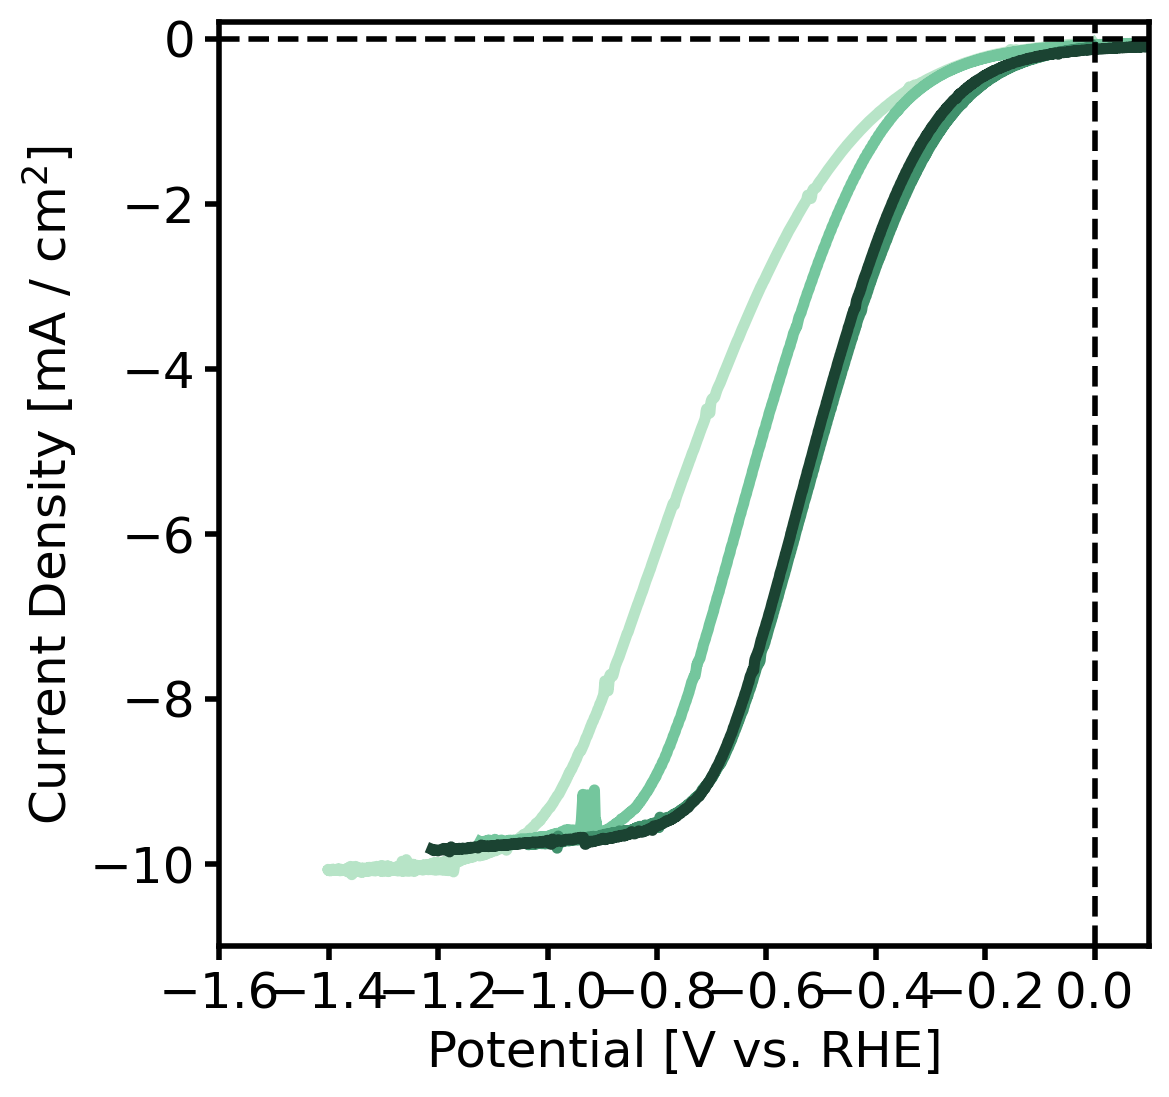

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
ref = 0.197     #standard reference electrode potential for w/e ref is used
pH =  6.8  #just pH of the solution
refi = ref + 0.059*pH  #units in volts
skippi = [66,72,63,63]
timei=[0,1,2,3,4,5,6,7,8,9,10,11,12]
# 1. Define your files and plot properties
filelist = [
     '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dry_1sun_FR_CV2_2_C01.mpt',
    '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dry_1SUN_FR_after_CP2_CV3_C01.mpt',
    '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dark_FR_AFTER_CP3_CV4_C01.mpt',
    '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_1sun_FR_AFTER_cp4_CV5_C01.mpt',

]
labels = [ '1','2c' '2', '3', '4']
colors = ['#0000ff','#d12d2d','#1D4499', "#1f77b4", "#2ca02c","#2ca02c"]
colors = ['#b7e4c7','#74c69d','#40916c', '#1b4332']
#colors = ['#E69F00']
yy=[35,40, 40, 40, 40, 40]
# Set up the static figure
plt.figure(figsize=(6, 6))

# Function to dynamically find the correct data starting row in each file
def find_header_line_number(filepath, encoding='ISO-8859-1'):
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if 'Ewe/V' in line and '<I>/mA' in line:
                    return i
    except FileNotFoundError:
        return -2
    return -1

# 2. Loop and plot each file
for jj, filename in enumerate(filelist):
    header_row_index = find_header_line_number(filename)
    
    if header_row_index == -2:
        print(f"Error: The file '{filename}' was not found. Please restore it to this folder.")
        continue
    if header_row_index == -1:
        print(f"Warning: Could not find header 'Ewe/V' in '{filename}'. Skipping.")
        continue
        
    try:
        # Read the file using ISO-8859-1 encoding to prevent decoding errors
        df = pd.read_csv(filename, skiprows=header_row_index, delimiter='\t', engine='python', encoding='ISO-8859-1')
        df= df[df['time/s'] >= yy[jj]]
        # Plot the static line
        plt.plot(df['Ewe/V']+refi, df['<I>/mA'], color=colors[jj], linewidth=4.0)
        
    except Exception as e:
        print(f"An error occurred while reading '{filename}': {e}")

# --- 3. Plot Configurations ---
plt.xlabel('Potential [V vs. RHE]', fontsize=18) 
plt.ylabel('Current Density [mA / cm$^2$]', fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.tick_params(axis='both', width=2, length=5)
#plt.legend(labels, loc="lower right")
#plt.axhline(y=-9, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-9.5, color='k', linestyle='--', linewidth=2)
#plt.axhline(y=-1, color='k', linestyle='--', linewidth=2)
#plt.axvline(x=-1.4, color='k', linestyle='--', linewidth=2)
plt.axhline(y=0, color='k', linestyle='--', linewidth=2)
plt.axvline(x=0, color='k', linestyle='--', linewidth=2)
plt.xlim(-1.6,0.1)
plt.ylim(-11,0.2)
# Adjust plot boundaries to match your original design
ax = plt.gca()
ax.spines['right'].set_visible(True)
ax.spines['top'].set_visible(True)
ax.spines['left'].set_color('k')
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_color('k')
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_color('k')
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_color('k')
ax.spines['bottom'].set_linewidth(2)
plt.savefig("FZ_FR_CV_withCP.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [37]:
filelist = [
     '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dry_1sun_FR_CP1_C01.mpt',
    '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dry_DARK_FZ_CP2_C01.mpt',
     '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dark_FZ_n1ma_CP3_C01.mpt',
     '20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_1sun_FR_n3ma_cp4_C01.mpt',

           ]

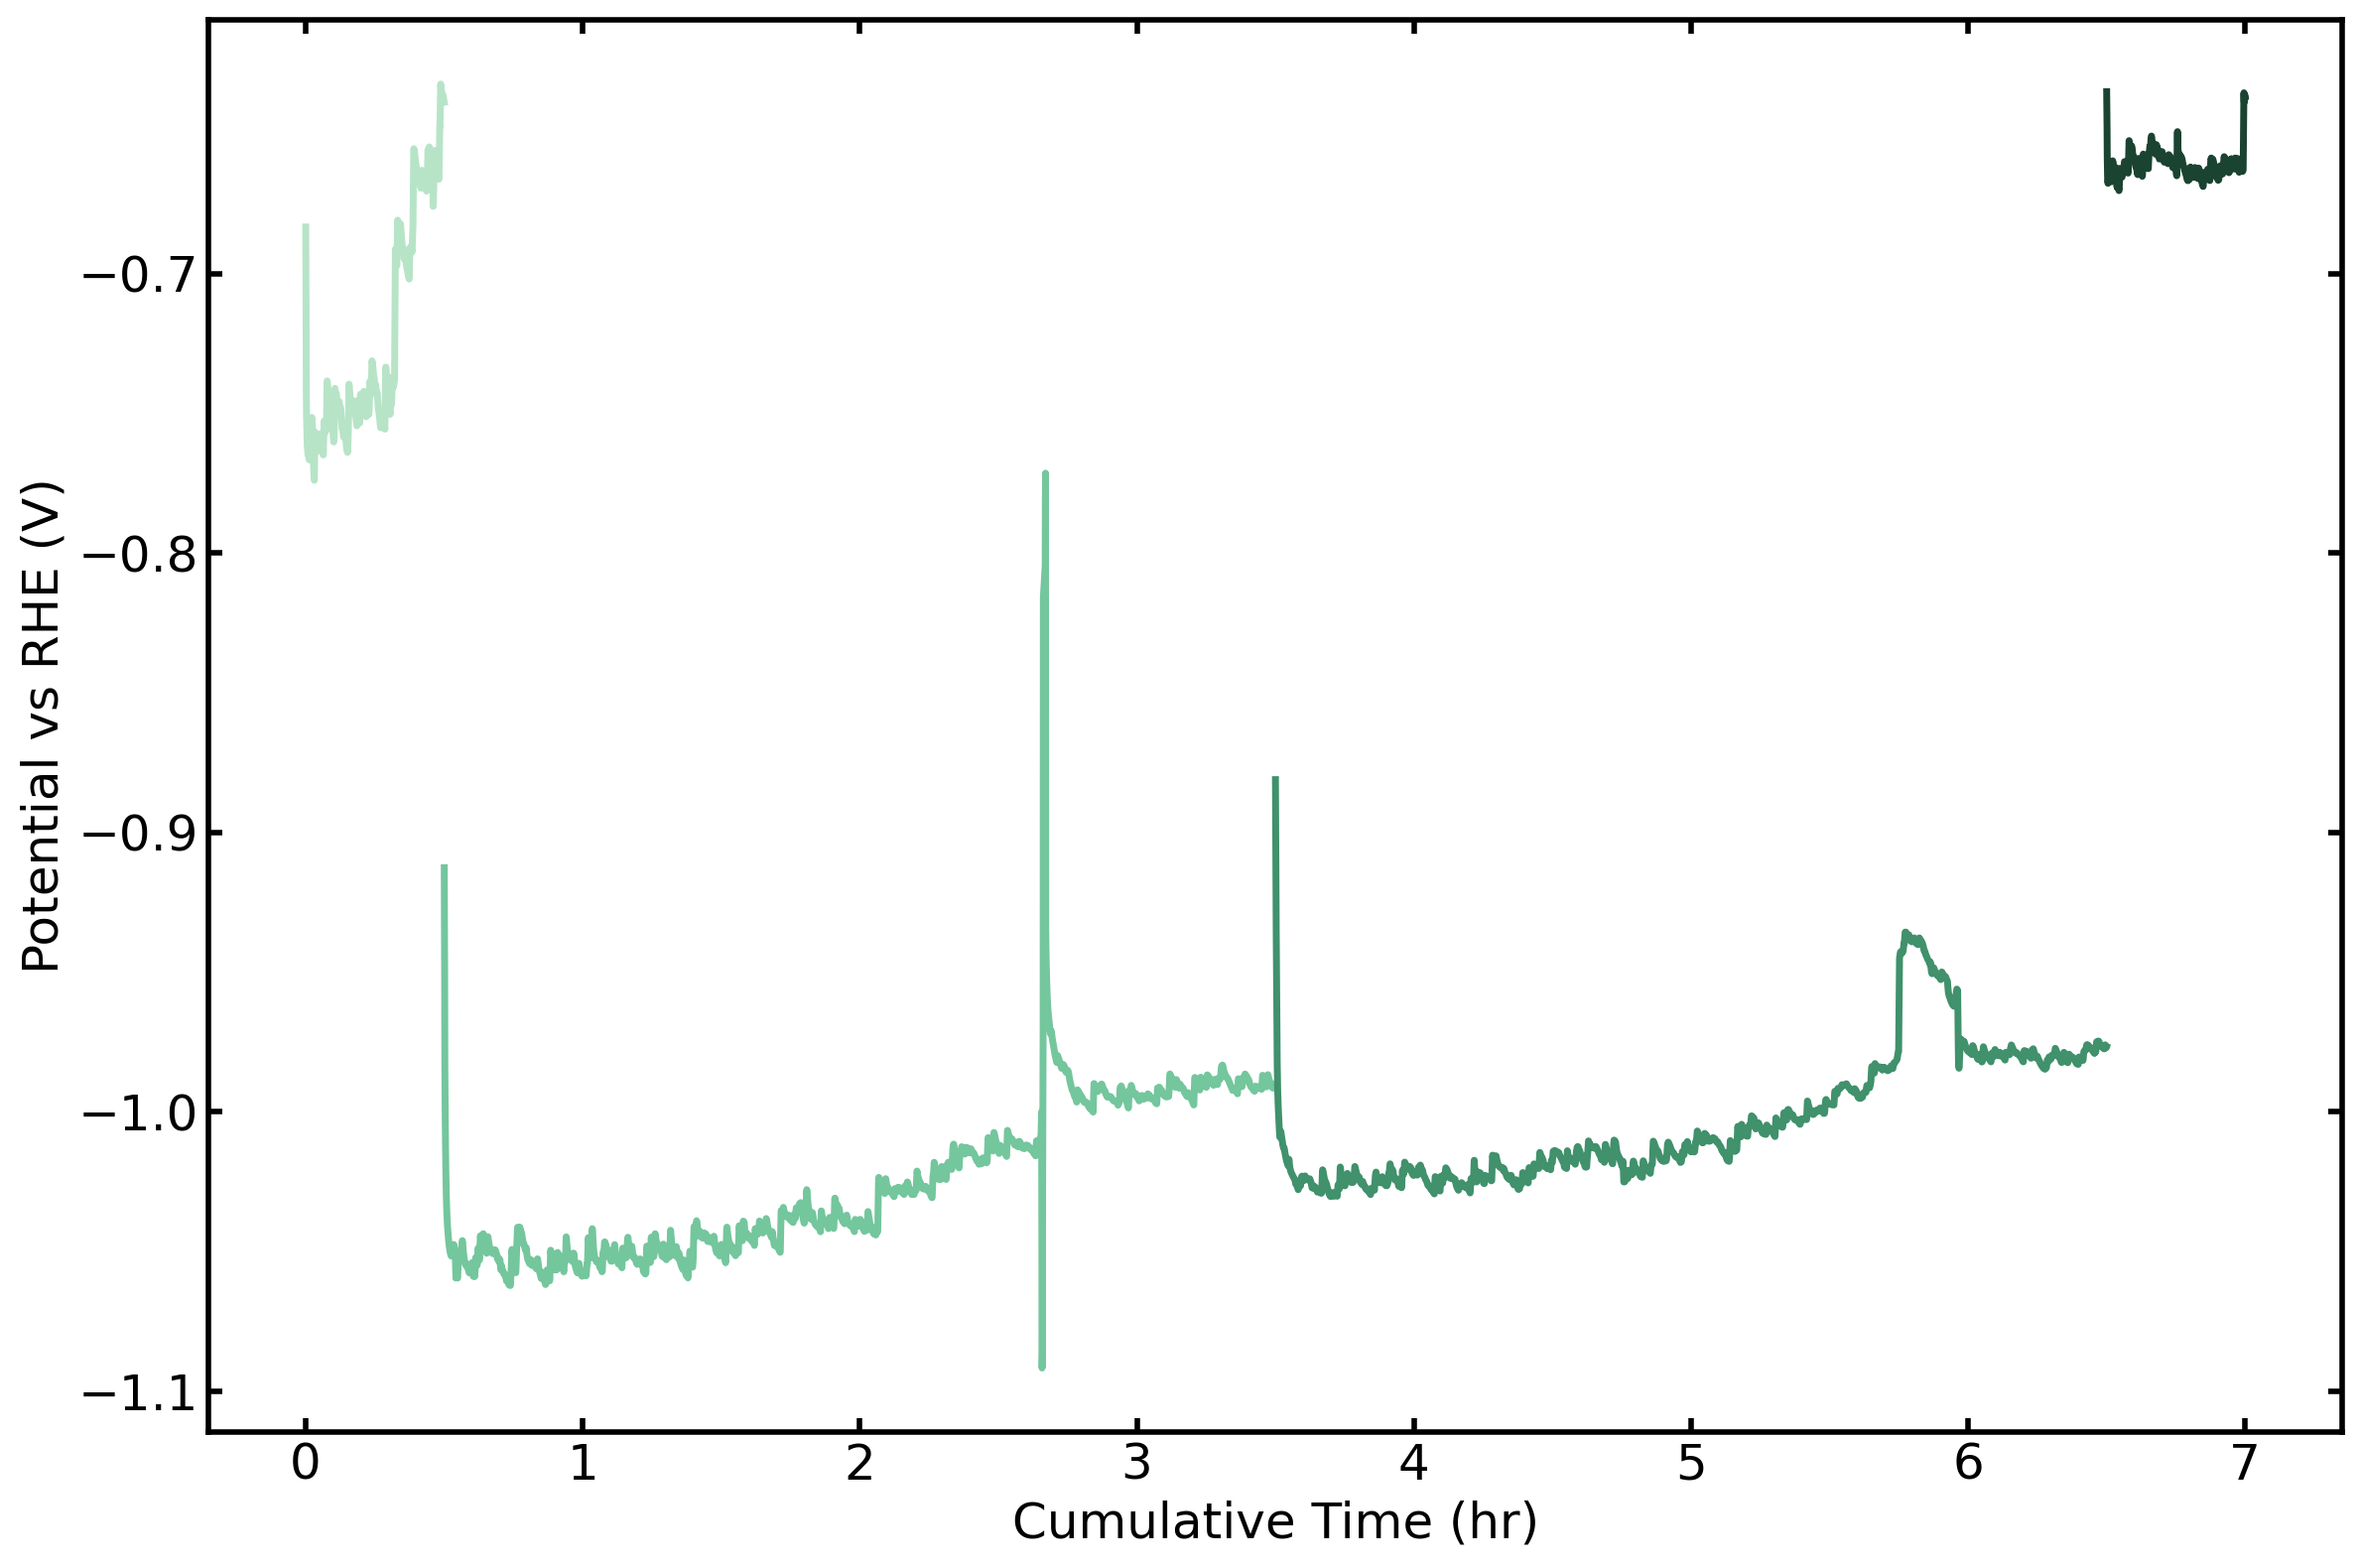

In [43]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 🔍 1. Helper Function: Dynamic Header Detection
# ==============================================================================
def find_header_row(filepath, expected_header_str, encoding="ISO-8859-1"):
    """
    Scans a file line-by-line to find the line number containing the expected column header.
    
    Args:
        filepath (str): Path to the experimental data file.
        expected_header_str (str): A string expected to uniquely identify the column header row.
        encoding (str): Text encoding.
        
    Returns:
        int: Number of rows to skip to reach the header line (returns 0 if not found).
    """
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if expected_header_str in line:
                    return i
    except FileNotFoundError:
        print(f"⚠️ Warning: File not found at {filepath}")
        return 0
    except Exception as e:
        print(f"⚠️ Error reading {filepath}: {e}")
        return 0
    return 0


# ==============================================================================
# 📈 2. Plotting Setup & Experimental Metadata
# ==============================================================================
time_offset_hours = 0.0

plot_labels = [
    '-3 mA light FR',
    '-1 mA dark FZ',
    '-1 mA dark FZ',
    '-3 mA light FR',
]

# Define reference potential (V vs. SHE) for each file
ref_values = [
    0.137,  # File 0 (Standard Ag/AgCl)
    0.137,  # File 1 (Standard Ag/AgCl)
    0.137,  # File 2 (Standard Ag/AgCl)
    0.000,  # File 3 (Adjusted reference value)
]

# pH value for each file (defaults to 6.8 if not provided)
pH_values = [6.8, 6.8, 6.8, 6.8]  

# Filtering & Smoothing Parameters
VALID_VOLTAGE_MIN = -1.9
VALID_VOLTAGE_MAX = 0.0
WINDOW_SIZE = 20

# Plotting aesthetics
cmap = ['#b7e4c7', '#74c69d', '#40916c', '#1b4332']
plt.figure(figsize=(12, 8))
plt.grid(False)


# ==============================================================================
# 🔄 3. Main Data Processing and Plotting Loop
# ==============================================================================
# Loop through the files (ensure filelist is defined in your active environment)
for jj in range(len(filelist)):
    filepath = filelist[jj]
    
    # --- Dynamic Skip Calculation ---
    # Scans file to find the header row containing '<Ewe/V>' dynamically.
    skip = find_header_row(filepath, expected_header_str='<Ewe/V>')
    
    try:
        # Read the file starting right at the dynamically discovered header
        df = pd.read_csv(filepath, skiprows=skip, encoding="ISO-8859-1", delimiter='\t')
        
        # Verify columns exist to avoid KeyErrors
        if '<Ewe/V>' not in df.columns or 'time/s' not in df.columns:
            print(f"⚠️ Skipping '{filepath}': Could not find expected column headers.")
            continue
            
        # Step 1: Filter out invalid voltage readings BEFORE smoothing
        df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()
        
        if df_filtered.empty:
            print(f"⚠️ Skipping '{filepath}': No valid data left after filtering.")
            continue
            
        # Step 2: Calculate the smoothed voltage on the FILTERED data
        df_filtered['voltage_smooth'] = df_filtered['<Ewe/V>'].rolling(
            window=WINDOW_SIZE, center=True, min_periods=1
        ).mean()
        
        # Step 3: Compute unique RHE conversion factors dynamically per file
        current_ref = ref_values[jj] if jj < len(ref_values) else 0.197
        current_pH = pH_values[jj] if jj < len(pH_values) else 6.8
        refi_current = current_ref + 0.059 * current_pH
        
        # Step 4: Map time coordinates
        current_time_hours = df_filtered['time/s'] / 3600
        x_values = current_time_hours + time_offset_hours
        
        current_label = plot_labels[jj] if jj < len(plot_labels) else f'File {jj+1}'
        
        # Step 5: Render Plot
        plt.plot(
            x_values, 
            df_filtered['voltage_smooth'] + refi_current, 
            color=cmap[jj % len(cmap)], 
            linewidth=2.5, 
            label=current_label
        )
        
        # Update the running time offset for sequential cumulative tracking
        if not current_time_hours.empty:
            time_offset_hours += current_time_hours.max()
            
    except Exception as e:
         print(f"⚠️ Failed to process file '{filepath}'. Error: {e}")



# ==============================================================================
# 🎨 4. Chart Formatting & Export
# ==============================================================================
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

plt.xlabel('Cumulative Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)

#plt.legend(fontsize=12, loc='best')
plt.tight_layout()

# Save output to PDF vector file
plt.savefig("wholetime_CP_FR_CP.pdf", format="pdf", bbox_inches="tight")
plt.show()


✅ Plotted First File ('20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_dry_1sun_FR_CP1_C01.mpt') with RHE correction of 0.538 V.
✅ Plotted Last File ('20261007_WE_3TAg_gridandlayer_augdep2_CE_ccloth2_RE_agacl_60mvmorpos_1sun_FR_n3ma_cp4_C01.mpt') with RHE correction of 0.401 V.


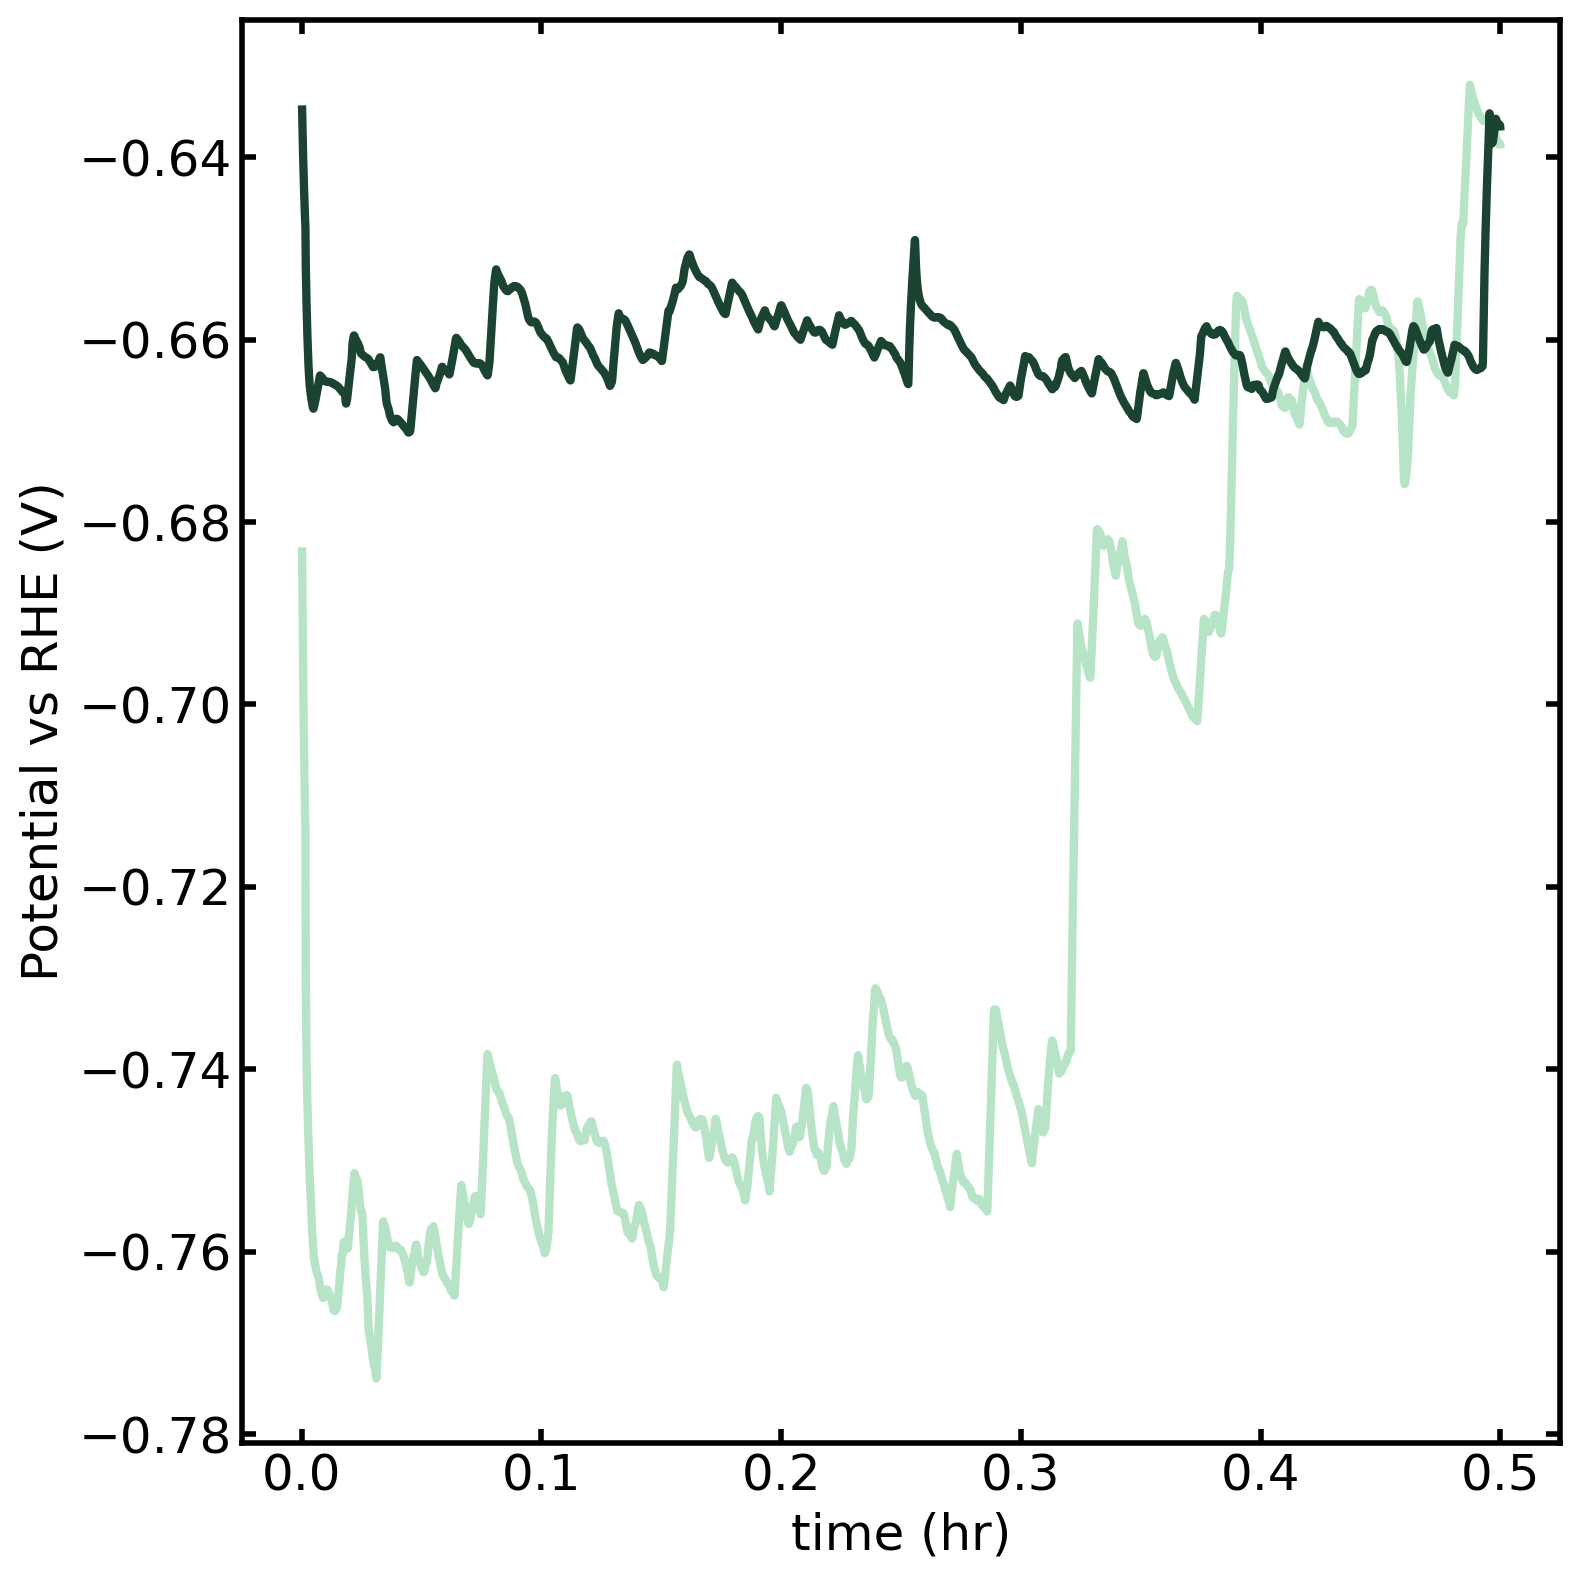

In [47]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 🔍 1. Helper Function: Dynamic Header Detection
# ==============================================================================
def find_header_row(filepath, expected_header_str, encoding="ISO-8859-1"):
    """
    Scans a file line-by-line to find the line number containing the expected column header.
    """
    try:
        with open(filepath, 'r', encoding=encoding) as f:
            for i, line in enumerate(f):
                if expected_header_str in line:
                    return i
    except FileNotFoundError:
        print(f"⚠️ Warning: File not found at {filepath}")
        return None
    except Exception as e:
        print(f"⚠️ Error reading {filepath}: {e}")
        return None
    return None


# ==============================================================================
# 📊 2. Setup Comparison Index
# ==============================================================================
# Ensure we have at least one file to process
total_files = len(filelist)
if total_files < 1:
    raise ValueError("The 'filelist' variable is empty. Please define at least one data file.")

# Identify the indices of the first and last files
first_idx = 0
last_idx = total_files - 1

# Define our target processing subset
# (Using a dictionary keeps track of the original index for reference values mapping)
comparison_targets = {
    "First File": first_idx,
    "Last File": last_idx
}

# If there is only 1 file in the list, just plot that one
if first_idx == last_idx:
    print("ℹ️ Note: Only 1 file found in 'filelist'. Plotting individual file.")
    comparison_targets = {"Only File": first_idx}


# ==============================================================================
# 📈 3. Plotting Setup & Experimental Metadata
# ==============================================================================
plot_labels = [
    '-3 mA light FR',
    '-1 mA dark FZ',
    '-1 mA dark FZ',
    '-3 mA light FR',
]

# Reference potentials (V vs. SHE) mapped to the original file indices
ref_values = [0.137, 0.137, 0.137, 0.000]
pH_values = [6.8, 6.8, 6.8, 6.8]  

# Filtering & Smoothing Parameters
VALID_VOLTAGE_MIN = -1.9
VALID_VOLTAGE_MAX = 0.0
WINDOW_SIZE = 20

# Distinct contrasting colors for comparing first vs last
comparison_colors = {
    "First File": '#b7e4c7',  # Crisp Blue
    "Last File": '#1b4332'    # Vivid Red
}
cmap = ['#b7e4c7', '#74c69d', '#40916c', '#1b4332']
plt.figure(figsize=(8, 8))
plt.grid(False)


# ==============================================================================
# 🔄 4. Processing & Overlay Plotting
# ==============================================================================
for label_key, file_idx in comparison_targets.items():
    filepath = filelist[file_idx]
    
    # 1. Dynamically locate header
    skip = find_header_row(filepath, expected_header_str='<Ewe/V>')
    if skip is None:
        continue
        
    try:
        # 2. Read the file
        df = pd.read_csv(filepath, skiprows=skip, encoding="ISO-8859-1", delimiter='\t')
        
        # 3. Filter out invalid voltage readings
        df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()
        
        if df_filtered.empty:
            print(f"⚠️ Warning: No valid data points found in '{filepath}' after filtering.")
            continue
            
        # 4. Smooth the voltage curve
        df_filtered['voltage_smooth'] = df_filtered['<Ewe/V>'].rolling(
            window=WINDOW_SIZE, center=True, min_periods=1
        ).mean()
        
        # 5. Extract unique RHE parameters using the target file's index
        current_ref = ref_values[file_idx] if file_idx < len(ref_values) else 0.197
        current_pH = pH_values[file_idx] if file_idx < len(pH_values) else 6.8
        refi_current = current_ref + 0.059 * current_pH
        
        # 6. Prepare x axis (No Cumulative Offset, starting both at t = 0)
        x_values = (df_filtered['time/s'] / 3600)
        
        # 7. Format Legend Label (combines sequence role with experimental identifier)
        run_name = plot_labels[file_idx] if file_idx < len(plot_labels) else f'File {file_idx+1}'
        display_label = f"{label_key} ({run_name})"
        
        # 8. Plot Overlay
        plt.plot(
            x_values, 
            df_filtered['voltage_smooth'] + refi_current, 
            color=comparison_colors.get(label_key, '#333333'), 
            linewidth=3.0, 
            label=display_label
        )
        
        print(f"✅ Plotted {label_key} ('{os.path.basename(filepath)}') with RHE correction of {refi_current:.3f} V.")
        
    except Exception as e:
         print(f"⚠️ Failed to process '{filepath}'. Error: {e}")


# ==============================================================================
# 🎨 5. Formatting & Save Comparison

plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

plt.xlabel('time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)

#plt.legend(fontsize=12, loc='best', frameon=True)
plt.tight_layout()

# Save comparison chart
plt.savefig("first_vs_last_CP_comparison.pdf", format="pdf", bbox_inches="tight")
plt.show()


In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import io
import os

# --- Plotting Setup ---
time_offset_hours = 0.0

plot_labels = [
    '-3 mA light FR',
    '-1 mA dark FZ',
    
    '-3 mA light FR',
]

# Setting our figure size
plt.figure(figsize=(12, 8))
plt.grid(False)

# ==========================================
# 📍 Reference Electrode & pH Setup per File
# ==========================================
# Define standard reference potential (V vs. SHE) for each file in your list.
# Adjust these values to match the specific reference electrode used in each run.
# (e.g., 0.197 for standard Ag/AgCl, or custom/altered values)
ref_values = [
    0.137,  # File 0 standard reference (Ag/AgCl)
    0.137,  # File 1 standard reference
    0.137,  # File 2 ALTERED reference (e.g., slightly drifted or different electrode)
    0.0,  # The reference electrode after was 0.3 versus the ref (0.06 at the start so adjusting by subtracting .2
]

# If pH differs between runs, define a list; otherwise, use a constant pH
pH_values = [6.8, 6.8, 6.8, 6.8]  

# Filtering & Smoothing Parameters
VALID_VOLTAGE_MIN = -1.9
VALID_VOLTAGE_MAX = 0.0
WINDOW_SIZE = 20

colors = ['#b7e4c7', '#74c69d', '#40916c', '#1b4332']
cmap = ['#b7e4c7', '#74c69d', '#40916c', '#1b4332']

# --- Plotting Loop with Dynamic Reference Conversion ---
for jj in range(len(filelist)):
    skip = 54 
    
    # 1. Read actual data file
    df = pd.read_csv(filelist[jj], skiprows=skip, encoding="ISO-8859-1", delimiter='\t')
    
    # Step 1: Filter out invalid voltage readings BEFORE smoothing
    df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()
    
    # Step 2: Calculate the smoothed voltage on the FILTERED data
    df_filtered['voltage_smooth'] = df_filtered['<Ewe/V>'].rolling(window=WINDOW_SIZE, center=True, min_periods=1).mean()
    
    # Step 3: Compute the unique conversion factor to RHE for THIS specific file
    # If filelist is longer than your ref_values array, fall back to a default value (0.197 V)
    current_ref = ref_values[jj] if jj < len(ref_values) else 0.197
    current_pH = pH_values[jj] if jj < len(pH_values) else 6.8
    
    # E_RHE = E_measured + E_ref + 0.059 * pH
    refi_current = current_ref + 0.059 * current_pH
    
    # Step 4: Plot the cleaned and smoothed data
    current_time_hours = df_filtered['time/s'] / 3600
    x_values = current_time_hours + time_offset_hours
    
    current_label = plot_labels[jj] if jj < len(plot_labels) else f'File {jj}'
    
    # Plot the smoothed data with its unique dynamic RHE correction applied
    plt.plot(
        x_values, 
        df_filtered['voltage_smooth'] + refi_current, 
        color=cmap[jj % len(cmap)], 
        linewidth=2.5, 
        label=current_label
    )
    
    # Update the offset for the next file based on the max time in the filtered data
    if not current_time_hours.empty:
        time_offset_hours += current_time_hours.max()

# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)

plt.xlabel('Cumulative Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
#plt.legend(fontsize=12, loc='best')  # Restored legend so you can verify labels
plt.tight_layout()
plt.savefig("wholetime_CP_FR_CP.pdf", format="pdf", bbox_inches="tight")
plt.show()

ParserError: Error tokenizing data. C error: Expected 1 fields in line 59, saw 29


In [90]:
filelist2 = [
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_part2_C01.mpt',
 '20260811_3TAgsdgrid_aglayer_803dep_ce_ccloth2_re_agagcl_withco2flow_8mlmin_1sun_FR_n3mA_CP_C01.mpt',
           ]

Filtering out data points outside the range: -10.0V to 0V


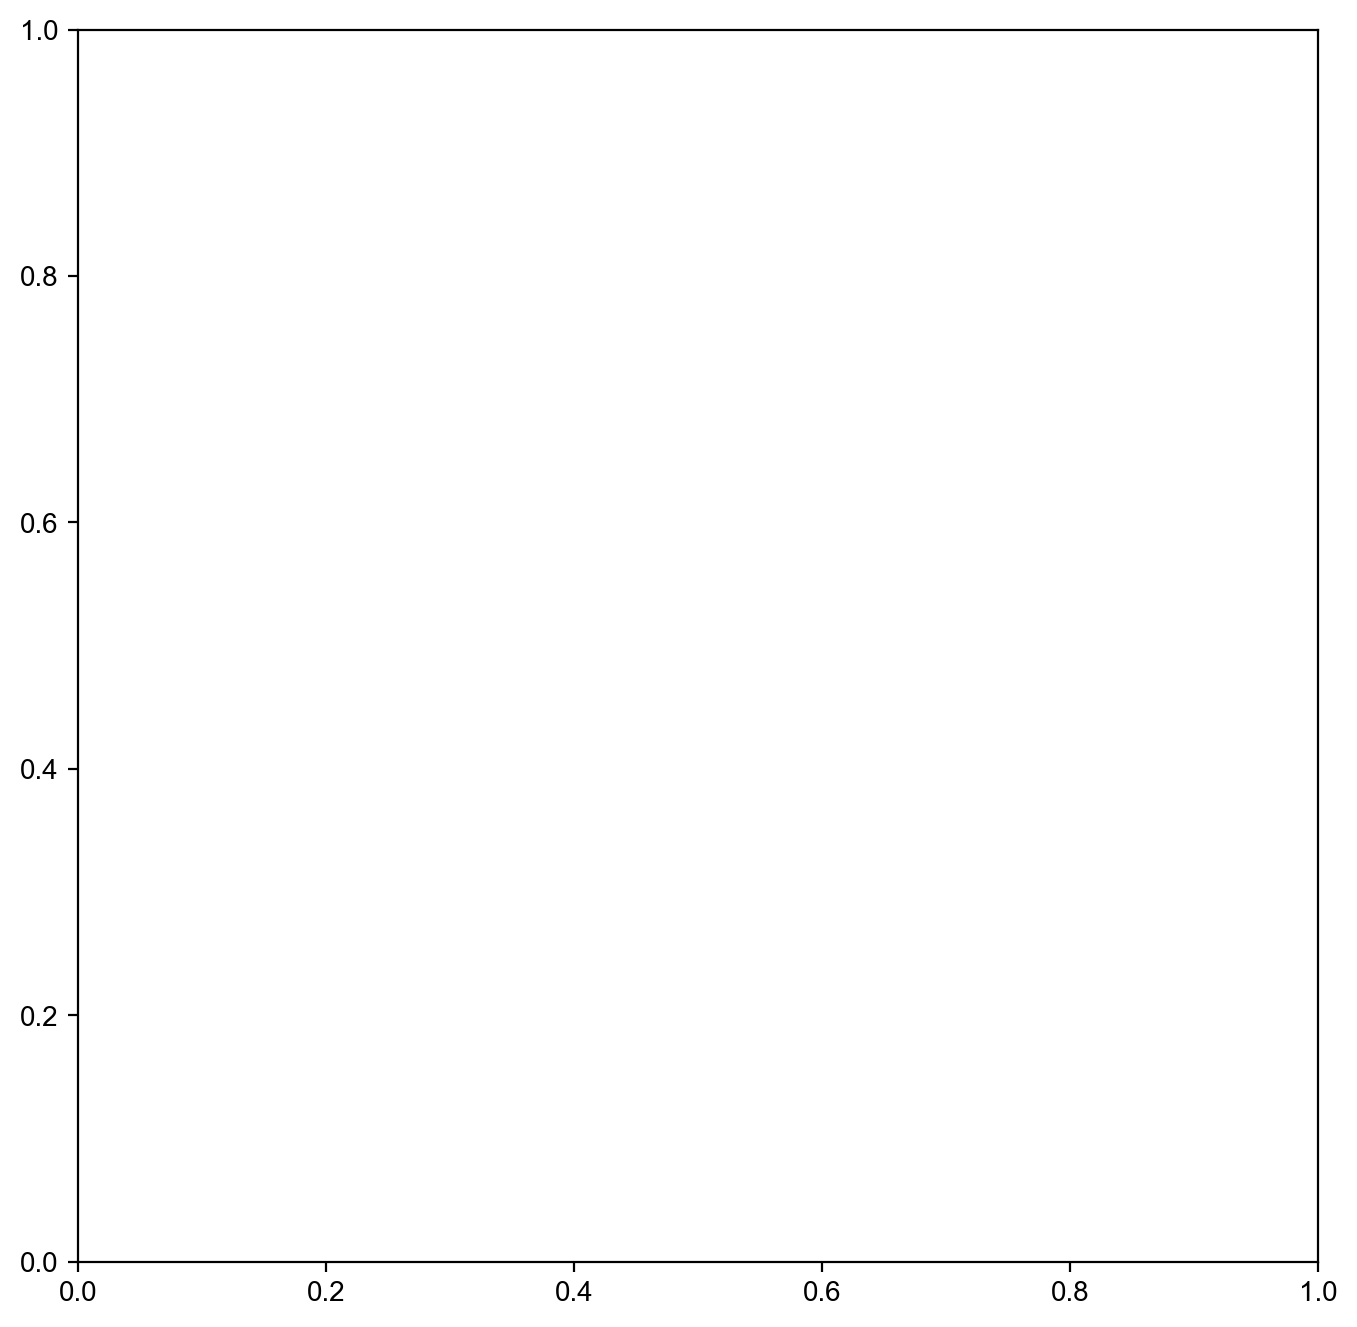

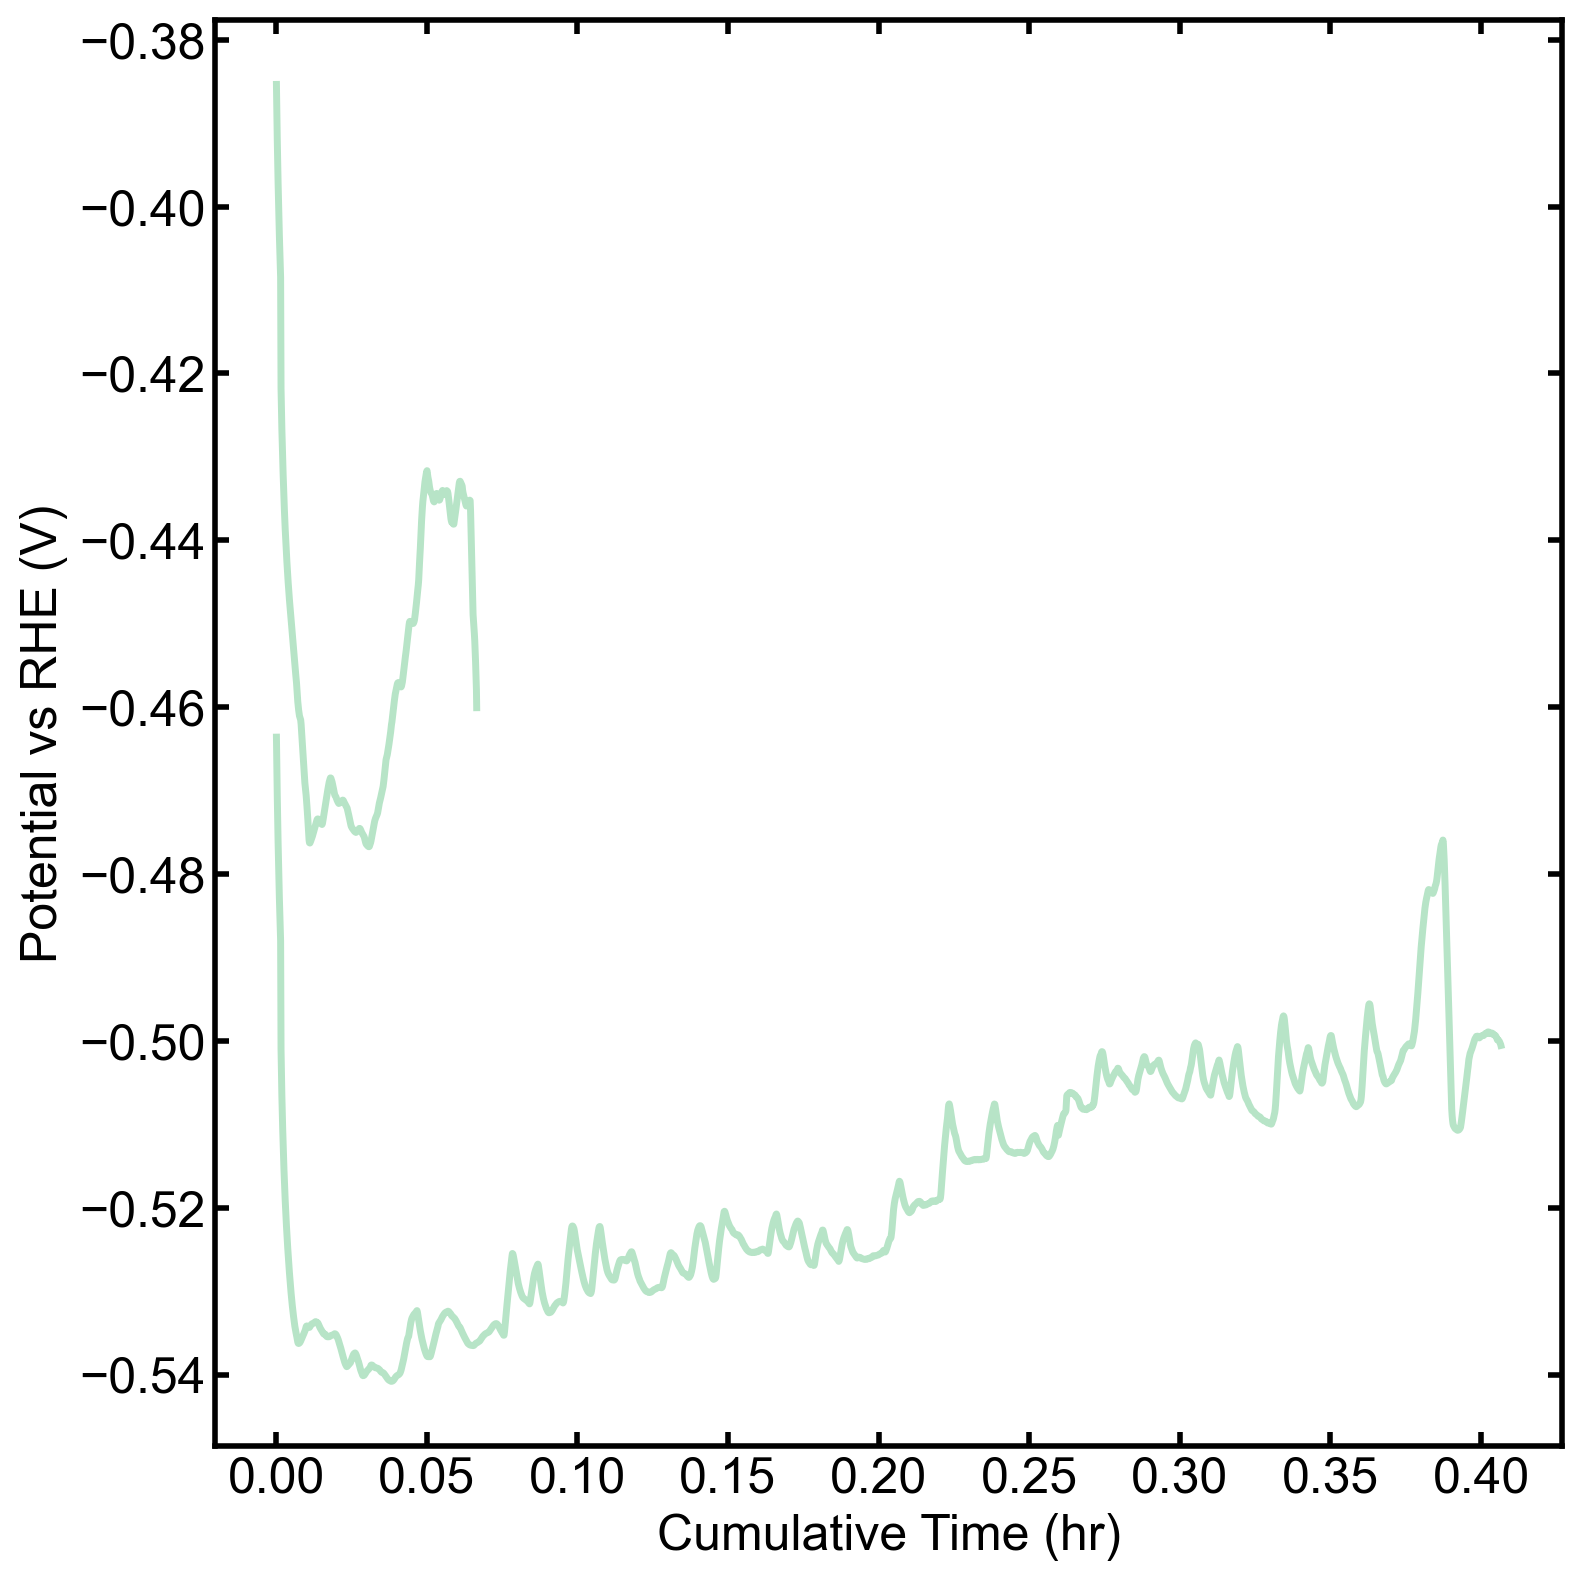

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
import io
import os

# --- Plotting Setup ---
time_offset_hours = 0.0

plot_labels = [
    '-3 mA light FR',
    '_nolegend_',
    '-3 mA light FR',
    '_nolegend_',
    '_nolegend_',
]

# Setting our figure size
plt.figure(figsize=(8, 8))
plt.grid(False)

# Standard reference electrode potential and pH conversions
ref = 0.197     # Standard reference electrode potential
pH = 6.8        # pH of the solution
refi = ref + 0.059 * pH  # Conversion factor to RHE (V)

# Filtering & Smoothing Parameters
VALID_VOLTAGE_MIN = -1.9
VALID_VOLTAGE_MAX = 0.0
WINDOW_SIZE = 20
colors = ['#b7e4c7','#74c69d','#74c69d', '#74c69d',]
colors = ['#b7e4c7','#74c69d','#40916c', '#1b4332']
cmap = ['#b7e4c7','#b7e4c7', '#1b4332','b', 'g', 'm', 'm', 'm', 'c', 'y']
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# IMPORTANT NOTE:
# This script assumes that the variable `filelist_MV782n2_OCV` is a list
# of valid file paths that `pd.read_csv` can access in your local environment.
# ==========================================

# Make sure this variable is defined and points to your real files
# Example:
# filelist_MV782n2_OCV = ['path/to/file1.csv', 'path/to/file2.csv', ...]
VALID_VOLTAGE_MIN = -10.0
VALID_VOLTAGE_MAX = 0
plt.figure(figsize=(8, 8))
plt.grid(False)

# --- Constants & Setup ---
ref = 0.197
pH = 6.8
refi = ref + 0.059 * pH
time_offset_hours = 0.0



# --- Plotting Loop with Filtering ---
print(f"Filtering out data points outside the range: {VALID_VOLTAGE_MIN}V to {VALID_VOLTAGE_MAX}V")

for jj in range(len(filelist2)):
    skip = 54 
    # 1. Read your actual data file
    df = pd.read_csv(filelist2[jj], skiprows=skip, encoding="ISO-8859-1", delimiter='\t')


# Step 1: Filter out invalid voltage readings BEFORE smoothing
    df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()
    
    # Step 2: Calculate the smoothed voltage on the FILTERED data
    df_filtered['voltage_smooth'] = df_filtered['<Ewe/V>'].rolling(window=WINDOW_SIZE, center=True, min_periods=1).mean()
    
    # Step 3: Plot the cleaned and smoothed data
    # FIX 1: We calculate time using df_filtered so the row count matches voltage_smooth
    current_time_hours = df_filtered['time/s'] / 3600

    x_values = current_time_hours 
    
    current_label = plot_labels[jj] if jj < len(plot_labels) else f'File {jj}'
    
    # Plot the smoothed data (thicker, solid line)
    # FIX 2: Removed [jj] index from current_label to pass the correct string
    plt.plot(
        x_values, 
        df_filtered['voltage_smooth'] + refi, 
        color=cmap[jj % len(cmap)], 
        linewidth=2.5, 
        label=current_label
    )
    if not current_time_hours.empty:
        time_offset_hours += current_time_hours.max()
# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
plt.xlabel('Cumulative Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
#plt.legend()
plt.tight_layout()
#plt.ylim(-0.8, -0.55)
plt.savefig("zoomed_voltage_after_ocv.pdf", format="pdf", bbox_inches="tight")

plt.show()




In [38]:
filelist_1= sorted(glob.glob('*.mpt'))
#FR_filelist
filelist_1 = '20240612_3TTiAg#1_plain_CV_1sun_with_glass_1_C01.mpt','20240612_3TTiAg#1_plain_OCV_1sun_no_glass_2_02_CV_C01.mpt'

Filtering out data points outside the range: -10.0V to 0.0V


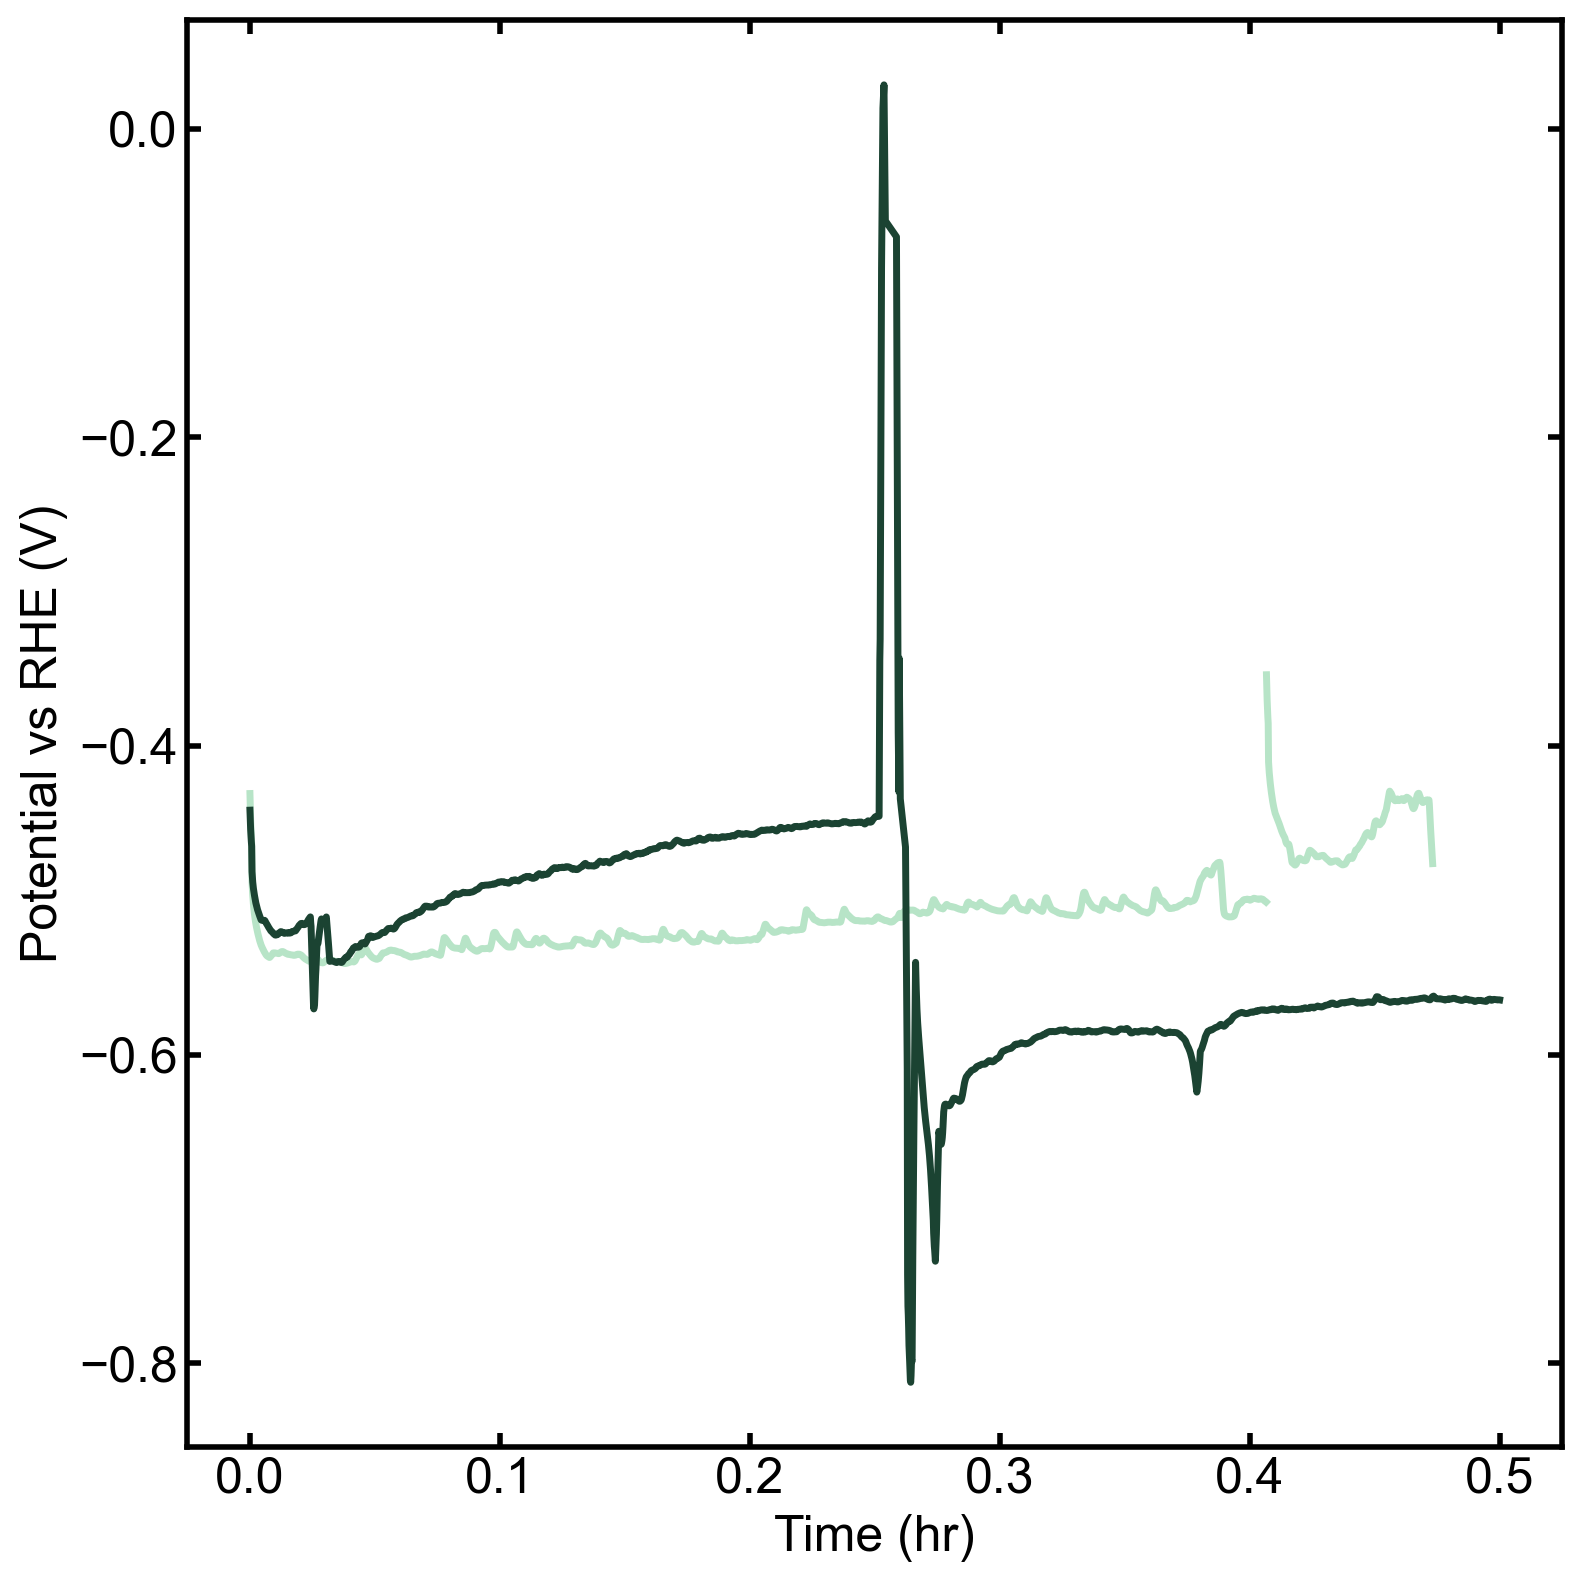

In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# This script assumes 'filelist_run12' and 'filelist_run3' are lists of file paths.
# Since the files were not provided, I have created dummy files for demonstration.
# Please replace these with your actual file lists.

filelist2 = [
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_C01.mpt',
 '20260814_3TAgsdgrid_aglayer_725dep1_ce_ccloth2_re_agagcl_10mlmin_withco2flow_1sun_FR_n3ma_CP1_part2_C01.mpt',

           ]
filelist3= [ '20260811_3TAgsdgrid_aglayer_803dep_ce_ccloth2_re_agagcl_withco2flow_8mlmin_1sun_FR_n3mA_CP_C01.mpt']

# --- Plotting Setup ---
plt.figure(figsize=(8, 8))
plt.grid(False)

# Standard reference electrode potential and pH conversions
ref = 0.197     # Standard reference electrode potential
pH = 6.8        # pH of the solution
refi = ref + 0.059 * pH  # Conversion factor to RHE (V)

# Filtering & Smoothing Parameters
VALID_VOLTAGE_MIN = -10.0
VALID_VOLTAGE_MAX = 0.0
WINDOW_SIZE = 10 # Using a smaller window for dummy data

# Define colors and labels
colors = ['#b7e4c7','#b7e4c7', '#1b4332']
labels = ['Run 1', 'Run 2', 'Run 3']

print(f"Filtering out data points outside the range: {VALID_VOLTAGE_MIN}V to {VALID_VOLTAGE_MAX}V")

# --- Plot Runs 1 and 2 Sequentially ---
time_offset_hours = 0.0
for i, filepath in enumerate(filelist2):
    df = pd.read_csv(filepath, skiprows=54, encoding="ISO-8859-1", delimiter='\t')
    
    # Filter, smooth, and plot
    df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()
    df_filtered['voltage_smooth'] = df_filtered['<Ewe/V>'].rolling(window=WINDOW_SIZE, center=True, min_periods=1).mean()
    
    current_time_hours = df_filtered['time/s'] / 3600
    x_values = current_time_hours + time_offset_hours
    
    plt.plot(
        x_values, 
        df_filtered['voltage_smooth'] + refi, 
        color=colors[i], 
        linewidth=2.5, 
        label=labels[i]
    )
    
    if not current_time_hours.empty:
        time_offset_hours += current_time_hours.max()

# --- Plot Run 3 Overlaid ---
for filepath in filelist3:
    df = pd.read_csv(filepath, skiprows=54, encoding="ISO-8859-1", delimiter='\t')
    
    # Filter, smooth, and plot
    df_filtered = df[(df['<Ewe/V>'] >= VALID_VOLTAGE_MIN) & (df['<Ewe/V>'] <= VALID_VOLTAGE_MAX)].copy()
    df_filtered['voltage_smooth'] = df_filtered['<Ewe/V>'].rolling(window=WINDOW_SIZE, center=True, min_periods=1).mean()
    
    # Plot without the time offset
    current_time_hours = df_filtered['time/s'] / 3600
    x_values = current_time_hours
    
    plt.plot(
        x_values, 
        df_filtered['voltage_smooth'] + refi, 
        color=colors[2], # Use the third color
        linewidth=2.5, 
        label=labels[2] # Use the third label
    )

# --- Formatting ---
plt.tick_params(axis='both', right=True, top=True, direction='in', width=2, length=5)
ax = plt.gca()
ax.spines['left'].set_linewidth(2)
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
plt.xlabel('Time (hr)', fontsize=18)
plt.ylabel('Potential vs RHE (V)', fontsize=18)
plt.yticks(fontsize=18)
plt.xticks(fontsize=18)
#plt.legend(fontsize=14)
plt.tight_layout()
plt.savefig("zoom_CP_FR_CP.pdf", format="pdf", bbox_inches="tight")
plt.show()

